In [2]:
import yaml
import pandas as pd
import numpy as np
import os
from collections import defaultdict
import matplotlib.pyplot as plt
top_level_directory = '/mnt/datasets/GNM/processed_data_6dof/processed_data_10hz'

# Label Distributions

## Labels across datasets

In [3]:
def count_labels(np_file, nav_type):
    '''
    count labels from the pickle file saved in the trajectory directory
    '''
    labels, cnts = np.unique(np_file[nav_type].to_numpy(), return_counts=True, sorted=True)
    total_samples = cnts.sum().item()
    idx_location = np.where(labels == True)[0]
    # print(idx_location)
    if len(idx_location) > 0:
        idx_to_use = idx_location[0]
    else:
        idx_to_use = -1
    
    # print(idx_to_use)
    if idx_to_use != -1:
        nav_cnt = cnts[idx_to_use].item()
    else:
        nav_cnt = 0

    return total_samples, nav_cnt


In [4]:
def get_env_variables(filepath):
    '''
    parses yaml file and returns the list of environment labels and object labels
    in that order
    '''
    with open(filepath) as f:
        trajectory_labels = yaml.safe_load(f)

    env_labels = trajectory_labels["Environment Labels"]
    obj_labels = trajectory_labels["Object Labels"]

    return env_labels, obj_labels

In [5]:
total_samples = 0
total_trajectories = 0
dynamics_labels = 0
policy_labels = 0
interaction_labels = 0
empty_labels = 0
env_labels, obj_labels = defaultdict(int), defaultdict(int)
for (dirpath, dirnames, filenames) in os.walk(top_level_directory):
    for filename in filenames:
        if filename == 'traj_data_frame_labels.pkl':
            filepath = os.path.join(dirpath, filename)
            labels = pd.read_pickle(filepath)
            traj_samples, traj_dynamics = count_labels(labels, 'dynamics')
            _, traj_policy = count_labels(labels, 'policy')
            _, traj_interaction = count_labels(labels, 'interaction')
            total_samples += traj_samples
            dynamics_labels += traj_dynamics
            policy_labels += traj_policy
            interaction_labels += traj_interaction
            empty_labels += len(labels[(labels['policy'] == False) & (labels['dynamics'] == False) & (labels['interaction'] == False)])
            total_trajectories += 1

        if filename == "traj_data_bag_labels.yaml":
            filepath = os.path.join(dirpath, filename)

            traj_env_labels, traj_obj_labels = get_env_variables(filepath)

            for i in traj_env_labels:
                env_labels[i] += 1
            for i in traj_obj_labels:
                obj_labels[i] += 1


## Distribution of Labels

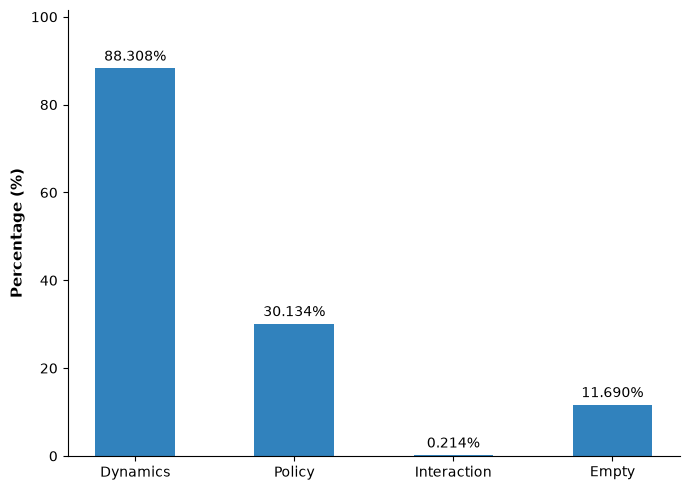

In [25]:
labels_cnt = np.array([dynamics_labels/total_samples*100, policy_labels/total_samples*100, interaction_labels/total_samples*100, empty_labels/total_samples*100])
# labels_cnt = np.array([dynamics_labels, policy_labels, interaction_labels, empty_labels])
label_names = ["Dynamics", "Policy", "Interaction", "Empty"]

fig, ax = plt.subplots(figsize=(7, 5))

# Plot vertical bars
bars = ax.bar(label_names, labels_cnt, color='#3182bd', width=0.5)

# Add the percentage values on top of each bar
ax.bar_label(bars, fmt='%.3f%%', padding=3, fontsize=10)

# Customize axes
ax.set_ylabel('Percentage (%)', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(labels_cnt) * 1.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()
# temp = labels_cnt

# print(temp/total_samples)
# print(temp / temp.sum())
# total_sum = labels_cnt.sum()
# # def pct(val):
#     # a = val/total_samples
#     # return f'{a:.1%}'
#     # return f"{val/total_samples:.1f}%"

# def show_raw_percentage(val):
#     raw_val = val / 100.0 * total_sum
#     return f'{raw_val*100:.2f}%'

# plt.pie(labels_cnt, labels=label_names, autopct=show_raw_percentage)
# plt.show()

In [26]:
env_labels, obj_labels

(defaultdict(int,
             {'indoor': 14,
              'sun': 703,
              'outdoor': 248,
              'off-road': 482,
              'underground': 3,
              'low-light': 3}),
 defaultdict(int,
             {'stairs': 23,
              'sidewalks': 212,
              'people': 140,
              'crosswalk': 83,
              'vehicles': 6,
              'crowd': 8}))

In [27]:
env_label_name, env_label_cnt = [],[]
for name, cnt in env_labels.items():
    env_label_name.append(name)
    env_label_cnt.append(cnt)

obj_label_name, obj_label_cnt = [],[]
for name, cnt in obj_labels.items():
    obj_label_name.append(name)
    obj_label_cnt.append(cnt)

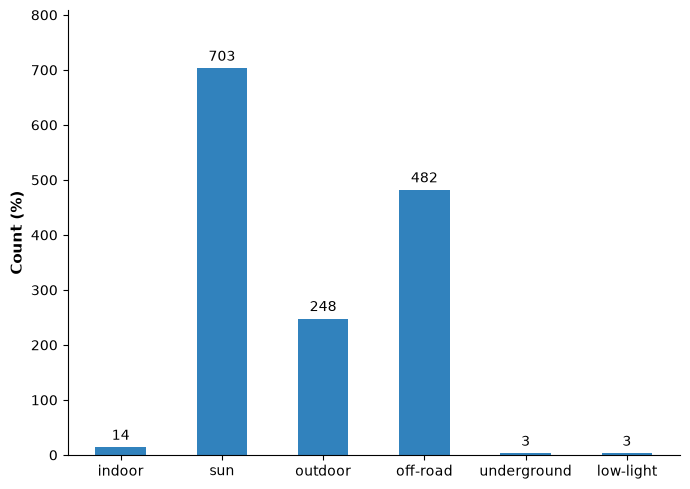

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

# Plot vertical bars
bars = ax.bar(env_label_name, env_label_cnt, color='#3182bd', width=0.5)

# Add the percentage values on top of each bar
ax.bar_label(bars, padding=3, fontsize=10)

# Customize axes
ax.set_ylabel('Count', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(env_label_cnt) * 1.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

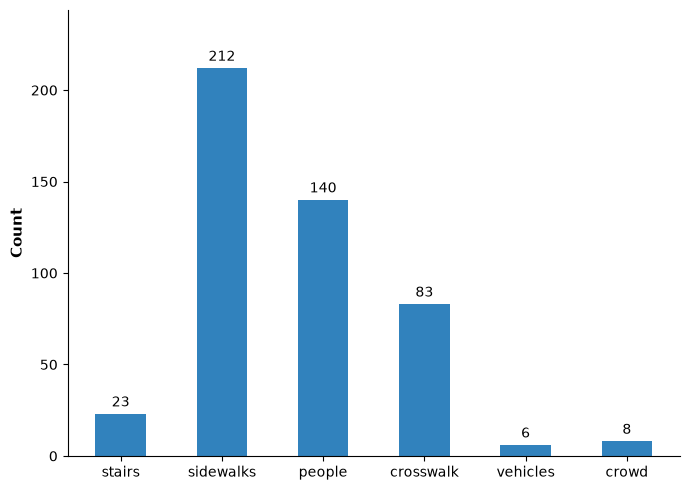

In [30]:
fig, ax = plt.subplots(figsize=(7, 5))

# Plot vertical bars
bars = ax.bar(obj_label_name, obj_label_cnt, color='#3182bd', width=0.5)

# Add the percentage values on top of each bar
ax.bar_label(bars, padding=3, fontsize=10)

# Customize axes
ax.set_ylabel('Count', fontsize=11, fontweight='bold')
ax.set_ylim(0, max(obj_label_cnt) * 1.15)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()